In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Возможные пути к файлу относительно папки notebooks/
file_candidates = [
    '../olx_laptops_expanded.csv',          # В корне проекта
    '../data/olx_laptops_expanded.csv',     # Внутри data/
    'olx_laptops_expanded.csv',             # В текущей папке
    '../data/laptops_final_clean_ml.csv'    # Очищенный датасет в data/
]

DATA_FILE = next((f for f in file_candidates if os.path.exists(f)), None)

if DATA_FILE is None:
    raise FileNotFoundError(f"Файл не найден. Текущая рабочая папка: {os.getcwd()}")

df_raw = pd.read_csv(DATA_FILE)
print(f"✅ Успешно загружен файл: {DATA_FILE}")
print(f"📊 Всего строк: {len(df_raw)}")
df_raw[['title', 'price_kzt', 'city']].head(3)

✅ Успешно загружен файл: ../olx_laptops_expanded.csv
📊 Всего строк: 5406


,title,price_kzt,city
0,ASUS Vivobook i3-1315U / 20GB RAM / SSD 512GB ...,170000,Алматы
1,Ноутбук для игр ASUS TUF Gaming 15 | Ryzen 5-7...,336000,Астана
2,Ноутбук Zik Ноутбуки в наличии.,30000,Павлодар


In [2]:
# 1. Извлечение бренда
def extract_brand(title: str) -> str:
    t = str(title).lower()
    if 'macbook' in t or 'apple' in t: return 'Apple'
    if any(k in t for k in ['asus', 'rog', 'tuf', 'zenbook', 'vivobook']): return 'ASUS'
    if any(k in t for k in ['lenovo', 'legion', 'thinkpad', 'ideapad', 'loq', 'yoga']): return 'Lenovo'
    if any(k in t for k in ['acer', 'nitro', 'predator', 'aspire', 'swift', 'extensa']): return 'Acer'
    if any(k in t for k in ['hp', 'victus', 'omen', 'pavilion', 'probook', 'elitebook']): return 'HP'
    if any(k in t for k in ['msi', 'katana', 'cyborg', 'stealth', 'raider', 'thin']): return 'MSI'
    if any(k in t for k in ['dell', 'alienware', 'latitude', 'vostro', 'xps', 'g15']): return 'Dell'
    if 'huawei' in t or 'matebook' in t: return 'Huawei'
    if 'samsung' in t: return 'Samsung'
    if 'honor' in t or 'magicbook' in t: return 'Honor'
    if 'xiaomi' in t or 'redmibook' in t: return 'Xiaomi'
    if 'gigabyte' in t or 'aorus' in t: return 'Gigabyte'
    return 'Other'

# 2. Извлечение продуктовой серии
def extract_series(title: str) -> str:
    t = str(title).lower()
    if 'macbook air' in t: return 'MacBook Air'
    if 'macbook pro' in t: return 'MacBook Pro'
    if 'legion' in t: return 'Lenovo Legion'
    if 'loq' in t: return 'Lenovo LOQ'
    if 'thinkpad' in t: return 'Lenovo ThinkPad'
    if 'ideapad' in t: return 'Lenovo IdeaPad'
    if 'rog' in t: return 'ASUS ROG'
    if 'tuf' in t: return 'ASUS TUF'
    if 'zenbook' in t: return 'ASUS ZenBook'
    if 'vivobook' in t: return 'ASUS VivoBook'
    if 'nitro' in t: return 'Acer Nitro'
    if 'predator' in t: return 'Acer Predator'
    if 'aspire' in t: return 'Acer Aspire'
    if 'swift' in t: return 'Acer Swift'
    if 'victus' in t: return 'HP Victus'
    if 'omen' in t: return 'HP Omen'
    if 'pavilion' in t: return 'HP Pavilion'
    if 'probook' in t: return 'HP ProBook'
    if 'elitebook' in t: return 'HP EliteBook'
    if any(k in t for k in ['katana', 'cyborg', 'thin']): return 'MSI Gaming'
    if any(k in t for k in ['alienware', 'g15', 'g16']): return 'Dell Gaming'
    if 'latitude' in t: return 'Dell Latitude'
    return 'Standard/Other'

# 3. Извлечение CPU с поколениями
def parse_cpu(title: str) -> str:
    t = str(title).lower()
    if 'm3' in t: return 'Apple M3'
    if 'm2' in t: return 'Apple M2'
    if 'm1' in t: return 'Apple M1'
    m_intel = re.search(r'\b(i3|i5|i7|i9)[ -]?(\d{1,2})\d{2,3}[a-z]*\b', t)
    if m_intel:
        return f"{m_intel.group(1).upper()} Gen {m_intel.group(2)}"
    if re.search(r'\bi9\b|core\s*i9', t): return 'Core i9'
    if re.search(r'\bi7\b|core\s*i7', t): return 'Core i7'
    if re.search(r'\bi5\b|core\s*i5', t): return 'Core i5'
    if re.search(r'\bi3\b|core\s*i3', t): return 'Core i3'
    m_ryzen = re.search(r'ryzen\s*([3579])[ -]?(\d)\d{3}[a-z]*', t)
    if m_ryzen:
        return f"Ryzen {m_ryzen.group(1)} {m_ryzen.group(2)}xxx"
    if re.search(r'ryzen\s*9|r9\b', t): return 'Ryzen 9'
    if re.search(r'ryzen\s*7|r7\b', t): return 'Ryzen 7'
    if re.search(r'ryzen\s*5|r5\b', t): return 'Ryzen 5'
    if re.search(r'ryzen\s*3|r3\b', t): return 'Ryzen 3'
    if 'celeron' in t: return 'Celeron'
    if 'pentium' in t: return 'Pentium'
    return 'Other'

# 4. Извлечение GPU
def extract_gpu(title: str) -> str:
    t = str(title).lower().replace('-', ' ').replace('/', ' ')
    for model in ['4090', '4080', '4070', '4060', '4050',
                  '3080', '3070', '3060', '3050 ti', '3050',
                  '2080', '2070', '2060',
                  '1660 ti', '1660', '1650 ti', '1650',
                  '1080', '1070', '1060', '1050 ti', '1050']:
        if f'rtx {model}' in t or f'rtx{model}' in t or f'gtx {model}' in t or f'gtx{model}' in t:
            return f"NVIDIA {model.upper()}"
        if re.search(rf'\b{model}\b', t) and any(k in t for k in ['rtx', 'gtx', 'nvidia', 'ti']):
            return f"NVIDIA {model.upper()}"
    if 'rtx 50' in t or 'rtx50' in t: return 'RTX 50xx'
    if 'rtx 40' in t or 'rtx40' in t: return 'RTX 40xx'
    if 'rtx 30' in t or 'rtx30' in t: return 'RTX 30xx'
    if 'rtx 20' in t or 'rtx20' in t: return 'RTX 20xx'
    if 'gtx 16' in t or 'gtx16' in t: return 'GTX 16xx'
    if 'gtx 10' in t or 'gtx10' in t: return 'GTX 10xx'
    if any(k in t for k in ['rtx', 'geforce', 'gtx']): return 'NVIDIA Other'
    if any(k in t for k in ['radeon', 'rx 5', 'rx 6', 'rx 7', 'vega']): return 'AMD Radeon'
    return 'Integrated'

# 5. Память (RAM)
def extract_ram(title: str) -> float:
    t = str(title).lower()
    slash = re.search(r'\b(4|6|8|12|16|20|24|32|40|48|64)\s*[/\\|]\s*(?:128|256|512|1000|1024|1tb|2tb|1тб|2тб)\b', t)
    if slash: return float(slash.group(1))
    m = re.search(r'\b(4|6|8|12|16|20|24|32|40|48|64)\s*(?:gb|гб|ram|озу|azu|ozu)\b', t)
    if m: return float(m.group(1))
    return np.nan

# 6. Накопитель (SSD / HDD)
def extract_storage(title: str) -> float:
    t = str(title).lower()
    m_tb = re.search(r'\b(1|2|4)\s*(?:tb|тб|терабайт)\b', t)
    if m_tb: return float(m_tb.group(1)) * 1024.0
    slash = re.search(r'\b(?:4|6|8|12|16|20|24|32|40|48|64)\s*[/\\|]\s*(128|256|512|1000|1024)\b', t)
    if slash:
        val = float(slash.group(1))
        return 1024.0 if val == 1000 else val
    m_ssd = re.search(r'\b(?:ssd|hdd|накопитель|память)?\s*(120|128|240|256|480|500|512|1000|1024)\s*(?:gb|гб|ssd|hdd)?\b', t)
    if m_ssd:
        val = float(m_ssd.group(1))
        return 1024.0 if val == 1000 else val
    return np.nan

# 7. Группа городов
def extract_city_group(city: str) -> str:
    c = str(city).strip()
    if c in ['Алматы', 'Астана', 'Шымкент']: return c
    if c in ['Караганда', 'Актобе', 'Тараз', 'Павлодар', 'Усть', 'Костанай', 'Атырау', 'Актау']:
        return 'Областные центры'
    return 'Другие регионы'

# 8. Частота экрана (Hz)
def extract_hz(title: str) -> float:
    t = str(title).lower()
    m = re.search(r'\b(120|144|165|240|300|360)\s*(?:hz|гц)\b', t)
    return float(m.group(1)) if m else 60.0

# Применяем все функции
df = df_raw.copy()
df['brand'] = df['title'].apply(extract_brand)
df['series'] = df['title'].apply(extract_series)
df['cpu'] = df['title'].apply(parse_cpu)
df['gpu'] = df['title'].apply(extract_gpu)
df['city_group'] = df['city'].apply(extract_city_group)
df['hz'] = df['title'].apply(extract_hz)

# Маркер игрового устройства
gaming_words = ['игров', 'gaming', 'tuf', 'rog', 'legion', 'nitro', 'predator', 'victus', 'omen', 'katana', 'cyborg', 'alienware', 'aorus', 'loq']
df['is_gaming'] = df.apply(
    lambda r: 1 if any(w in str(r['title']).lower() for w in gaming_words) or r['gpu'] != 'Integrated' else 0, axis=1
)

# Маркер состояния
df['has_defect'] = df['title'].apply(lambda t: 1 if any(w in str(t).lower() for w in ['дефект', 'сломан', 'не работает', 'скол', 'трещин', 'запчаст', 'ремонт', 'битый', 'нет клавиш']) else 0)
df['is_pristine'] = df['title'].apply(lambda t: 1 if any(w in str(t).lower() for w in ['новый', 'запечатан', 'идеал', 'в идеале', 'чек', 'гарантия']) else 0)
df['condition_score'] = df['is_pristine'] - df['has_defect']

# Память и заполнение пропусков
df['ram_gb'] = df['title'].apply(extract_ram)
df['storage_gb'] = df['title'].apply(extract_storage)
df['ram_gb'] = df.groupby('is_gaming')['ram_gb'].transform(lambda s: s.fillna(16.0 if s.name == 1 else 8.0))
df['storage_gb'] = df.groupby('is_gaming')['storage_gb'].transform(lambda s: s.fillna(512.0 if s.name == 1 else 256.0))

print("Feature Engineering успешно завершен! Все признаки созданы.")

Feature Engineering успешно завершен! Все признаки созданы.


Строк до фильтрации: 5406
Отсечено ценовых выбросов: 217 (4.01%)
Строк после удаления аномалий: 5189


C:\Users\Sayat\AppData\Local\Temp\ipykernel_5316\2734789651.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean[df_clean['brand'].isin(top_brands)], x='brand', y='price_kzt', ax=axes[1], palette='viridis')


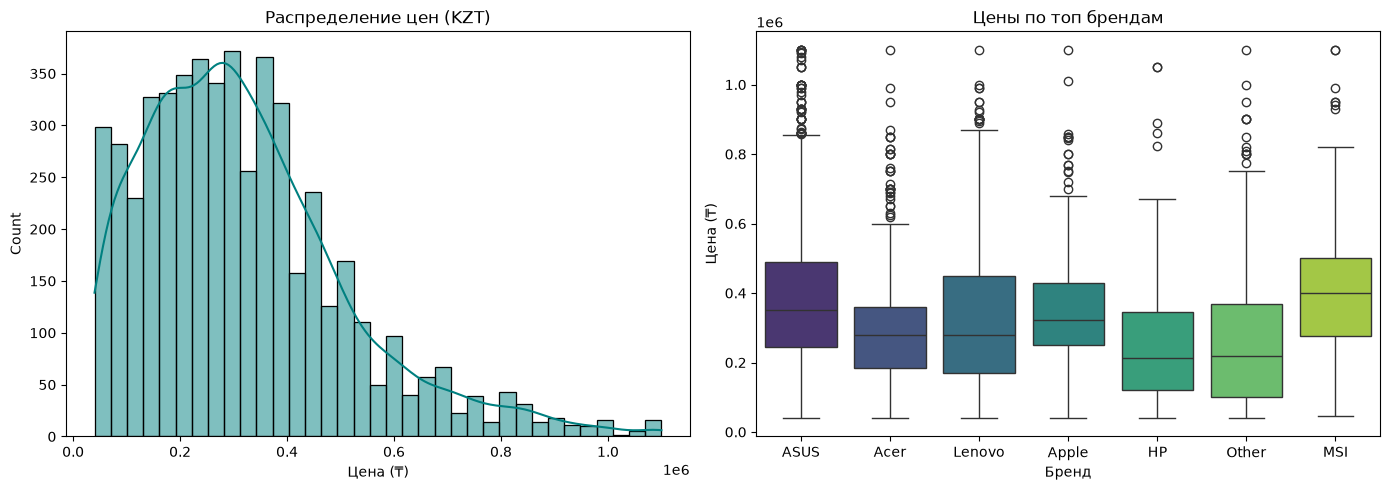

✅ Готово! Очищенный датасет сохранен в файл: laptops_final_clean_ml.csv
📊 Размер сохраненного файла: 5189 строк, 18 столбцов.


In [4]:
# Задаем границы фильтрации цен:
# 40 000 KZT — отсекает запчасти, сломанные платы, планшеты
# 1 100 000 KZT — отсекает штучные кастомные сеты за 1.5 - 3 млн
lower_bound = 40000
upper_bound = 1100000

anomalies_mask = (df['price_kzt'] < lower_bound) | (df['price_kzt'] > upper_bound)
print(f"Строк до фильтрации: {len(df)}")
print(f"Отсечено ценовых выбросов: {anomalies_mask.sum()} ({anomalies_mask.mean()*100:.2f}%)")

df_clean = df[~anomalies_mask].copy()
print(f"Строк после удаления аномалий: {len(df_clean)}")

# Быстрая визуализация основных зависимостей
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean['price_kzt'], bins=35, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Распределение цен (KZT)')
axes[0].set_xlabel('Цена (₸)')

top_brands = df_clean['brand'].value_counts().head(7).index
sns.boxplot(data=df_clean[df_clean['brand'].isin(top_brands)], x='brand', y='price_kzt', ax=axes[1], palette='viridis')
axes[1].set_title('Цены по топ брендам')
axes[1].set_xlabel('Бренд')
axes[1].set_ylabel('Цена (₸)')
plt.tight_layout()
plt.show()

# Сохраняем очищенный датасет со всеми готовыми признаками на диск
output_csv = 'laptops_final_clean_ml.csv'
df_clean.to_csv(output_csv, index=False, encoding='utf-8-sig')

print(f"✅ Готово! Очищенный датасет сохранен в файл: {output_csv}")
print(f"📊 Размер сохраненного файла: {len(df_clean)} строк, {len(df_clean.columns)} столбцов.")

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Список признаков для обучения
features = [
    'brand', 'series', 'cpu', 'gpu', 'city_group', 
    'ram_gb', 'storage_gb', 'hz', 'is_gaming', 'condition_score'
]

X = df_clean[features]
y = df_clean['price_kzt']

# Обучаем модели на log1p(y) для устранения скошенности
y_log = np.log1p(y)

# 80% Train, 20% Test
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)
y_test_real = np.expm1(y_test_log)

cat_cols = ['brand', 'series', 'cpu', 'gpu', 'city_group']
num_cols = ['ram_gb', 'storage_gb', 'hz', 'is_gaming', 'condition_score']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

print(f"Размер Train: {X_train.shape[0]} | Размер Test: {X_test.shape[0]}")

Размер Train: 4151 | Размер Test: 1038


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "1. Baseline: Ridge Regression": Ridge(alpha=1.0),
    "2. Random Forest Regressor": RandomForestRegressor(n_estimators=180, max_depth=14, random_state=42, n_jobs=-1),
    "3. Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=300, learning_rate=0.06, max_depth=6, subsample=0.85, random_state=42)
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('reg', model)
    ])
    
    pipe.fit(X_train, y_train_log)
    pred_real = np.expm1(pipe.predict(X_test))
    
    mae = mean_absolute_error(y_test_real, pred_real)
    rmse = np.sqrt(mean_squared_error(y_test_real, pred_real))
    r2 = r2_score(y_test_real, pred_real)
    mape = np.mean(np.abs((y_test_real - pred_real) / y_test_real)) * 100
    hit_rate = np.mean(np.abs((y_test_real - pred_real) / y_test_real) <= 0.15) * 100
    
    results.append({
        "Модель": name,
        "MAE (₸)": f"{mae:,.0f} ₸",
        "RMSE (₸)": f"{rmse:,.0f} ₸",
        "R²": round(r2, 3),
        "MAPE (%)": f"{mape:.1f}%",
        "Hit Rate @ 15%": f"{hit_rate:.1f}%"
    })

df_metrics = pd.DataFrame(results)
display(df_metrics)

,Модель,MAE (₸),RMSE (₸),R²,MAPE (%),Hit Rate @ 15%
0,1. Baseline: Ridge Regression,"94,667 ₸","141,566 ₸",0.430,37.3%,32.5%
1,2. Random Forest Regressor,"89,190 ₸","137,142 ₸",0.465,35.6%,36.8%
2,3. Gradient Boosting Regressor,"85,348 ₸","131,461 ₸",0.509,34.2%,39.1%


In [7]:
import joblib

best_model = GradientBoostingRegressor(
    n_estimators=300, 
    learning_rate=0.06, 
    max_depth=6, 
    subsample=0.85, 
    random_state=42
)

final_pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', best_model)
])

final_pipeline.fit(X_train, y_train_log)

joblib.dump(final_pipeline, 'laptop_price_model.pkl')
print("Модель успешно сохранена в файл laptop_price_model.pkl!")

Модель успешно сохранена в файл laptop_price_model.pkl!
